# 🎓 Lab 2 · Will This Student Pass? (Classification)

**AI & Data Science Course · Machine Learning** — Trainer: **Arslan Ahmed**

In Lab 1 we predicted a **number** (house price). Today we predict a **group**: will a student **Pass** or **Fail**?

The idea: if we can find students who are **at risk of failing early**, trainers can help them in time. 💡

We follow the same 10 steps:

1. Understand the problem
2. Load the data
3. Clean the data
4. Explore the data with charts
5. Prepare the data for the model
6. Split the data into train and test
7. Train the model
8. Check how good the model is
9. Try more models
10. Save the model and **test it live** with your own student

> **How to run:** click a code cell and press **Shift + Enter**. Run the cells **from top to bottom**. Read the text above each cell first.

## Step 1 · Understand the problem

- **Features (X):** information about a student — study hours, attendance, quiz marks, assignments, laptop, internet…
- **Target (y):** `result` → **Pass** or **Fail**
- The answer is a **group (class)**, not a number, so this is a **classification** problem.

> 📘 **Classification:** predicting which group something belongs to. Examples: spam / not spam, pass / fail, cat / dog / bird.
> 📘 **Binary classification:** only **two** groups (here: Pass and Fail).

ℹ️ This is a practice dataset made for this course. It contains mistakes on purpose, so you can practise cleaning.

## Step 2 · Load the data

> 📘 **pandas** is the Python library for tables. We write `import pandas as pd` to use the short name `pd`.

In [1]:
import pandas as pd

df = pd.read_csv("saylani_student_results.csv")
df.head()

,student_id,city,age,education,study_hours_week,attendance_pct,quiz_avg,assignments_done,has_laptop,has_internet,part_time_job,programming_before,travel_time_min,final_exam_score,result
0,SMIT-2177,Sukkur,24,Bachelors,3.4,87.0,76.0,6,No,Yes,Yes,No,30,59.0,Pass
1,SMIT-2510,Sukkur,21,Bachelors,11.9,100.0,91.0,7,No,No,No,Yes,5,81.0,Pass
2,SMIT-2846,Sukkur,22,Matric,2.3,83.0,54.0,8,Yes,No,No,No,15,55.0,Pass
3,SMIT-2600,Sukkur,24,Bachelors,5.0,72.0,45.0,5,Yes,No,No,No,5,48.0,Fail
4,SMIT-2012,Rohri,24,Bachelors,0.0,51.0,33.0,4,Yes,Yes,Yes,No,86,22.0,Fail


Keep `saylani_student_results.csv` in the **same folder** as this notebook.

| Column | Meaning |
|---|---|
| `student_id` | ID of the student (only a name) |
| `city` | City the student comes from |
| `age` | Age in years |
| `education` | Matric < Intermediate < Bachelors < Masters |
| `study_hours_week` | Hours of self-study per week |
| `attendance_pct` | Class attendance in % |
| `quiz_avg` | Average quiz marks (out of 100) |
| `assignments_done` | Assignments submitted (out of 10) |
| `has_laptop`, `has_internet` | Yes / No |
| `part_time_job` | Does the student also work? Yes / No |
| `programming_before` | Did the student learn programming before? Yes / No |
| `travel_time_min` | Minutes to travel to class |
| `final_exam_score` | Marks in the final exam ⚠️ (we will talk about this) |
| `result` | 🎯 **Pass or Fail — this is what we want to predict** |

In [2]:
print("Students:", df.shape[0])
print("Columns :", df.shape[1])
df.info()

Students: 1012
Columns : 15
<class 'pandas.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          1012 non-null   str    
 1   city                1012 non-null   str    
 2   age                 1012 non-null   int64  
 3   education           1012 non-null   str    
 4   study_hours_week    1012 non-null   float64
 5   attendance_pct      983 non-null    float64
 6   quiz_avg            972 non-null    float64
 7   assignments_done    1012 non-null   int64  
 8   has_laptop          992 non-null    str    
 9   has_internet        1012 non-null   str    
 10  part_time_job       1012 non-null   str    
 11  programming_before  1012 non-null   str    
 12  travel_time_min     1012 non-null   int64  
 13  final_exam_score    1012 non-null   float64
 14  result              1012 non-null   str    
dtypes: float64(4), int64(3), str(8)
memory

In [3]:
df.describe()

,age,study_hours_week,attendance_pct,quiz_avg,assignments_done,travel_time_min,final_exam_score
count,1012.000000,1012.000000,983.000000,972.000000,1012.000000,1012.000000,1012.000000
mean,21.996047,5.653162,74.939980,59.277778,6.282609,42.182806,56.458498
std,3.045969,3.757251,12.951557,13.687366,2.371771,21.911818,18.211399
min,16.000000,-5.000000,36.000000,20.000000,0.000000,5.000000,5.000000
25%,20.000000,2.900000,66.000000,50.000000,5.000000,25.000000,45.000000
50%,22.000000,5.400000,75.000000,59.000000,6.000000,39.000000,56.000000
75%,24.000000,8.100000,84.000000,68.000000,8.000000,59.000000,69.000000
max,32.000000,22.500000,150.000000,100.000000,10.000000,113.000000,100.000000


🔍 **Look carefully:**
- `attendance_pct` max is **150%**. Attendance cannot be more than 100%!
- `study_hours_week` min is **−5**. Hours cannot be negative.
- Some columns have fewer values than 1012 → there are **missing values**.

## Step 3 · Clean the data

### 3.1 Remove duplicate rows

In [4]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Students after removing duplicates:", len(df))

Duplicate rows: 12
Students after removing duplicates: 1000


### 3.2 Fix the target column `result`

In [5]:
df["result"].value_counts()

result
Pass     634
Fail     326
pass       9
PASS       8
Fail       7
Pass       6
FAIL       6
fail       4
Name: count, dtype: int64

The same answer is written in different ways: `Pass`, `PASS`, `pass`, `Pass ` (with a space). Let's make them all the same.

In [6]:
df["result"] = df["result"].str.strip().str.title()     # remove spaces, then "pass" → "Pass"
df["result"].value_counts()

result
Pass    657
Fail    343
Name: count, dtype: int64

### 3.3 Fix the spelling of cities

In [7]:
df["city"] = df["city"].str.strip().str.title()
df["city"].value_counts()

city
Sukkur       405
Khairpur     171
Shikarpur    158
Rohri        144
Larkana      122
Name: count, dtype: int64

### 3.4 Fix impossible values
We do not know the real attendance or study hours for these students, so we change the wrong values to **missing** and fill them later.

> 📘 **NaN** = "Not a Number" = an **empty / missing** value. To make NaN we use **NumPy**, the Python library for numbers and maths.

In [8]:
import numpy as np

df.loc[df["attendance_pct"] > 100, "attendance_pct"] = np.nan
df.loc[df["study_hours_week"] < 0, "study_hours_week"] = np.nan

print("Max attendance now :", df["attendance_pct"].max())
print("Min study hours now:", df["study_hours_week"].min())

Max attendance now : 100.0
Min study hours now: 0.0


### 3.5 Remove columns we should not use
- `student_id` is just a name. There is nothing to learn from it.
- `final_exam_score` is **how the result is decided** (a high score = Pass). But we want to predict the result **before** the final exam, to help students in time. At that moment the final score **does not exist yet**.
  Using it would be **data leakage** — the model would be "cheating".

In [9]:
df = df.drop(columns=["student_id", "final_exam_score"])
df.head()

,city,age,education,study_hours_week,attendance_pct,quiz_avg,assignments_done,has_laptop,has_internet,part_time_job,programming_before,travel_time_min,result
0,Sukkur,24,Bachelors,3.4,87.0,76.0,6,No,Yes,Yes,No,30,Pass
1,Sukkur,21,Bachelors,11.9,100.0,91.0,7,No,No,No,Yes,5,Pass
2,Sukkur,22,Matric,2.3,83.0,54.0,8,Yes,No,No,No,15,Pass
3,Sukkur,24,Bachelors,5.0,72.0,45.0,5,Yes,No,No,No,5,Fail
4,Rohri,24,Bachelors,0.0,51.0,33.0,4,Yes,Yes,Yes,No,86,Fail


### 3.6 Check missing values

In [10]:
df.isnull().sum()

city                   0
age                    0
education              0
study_hours_week       2
attendance_pct        31
quiz_avg              40
assignments_done       0
has_laptop            20
has_internet           0
part_time_job          0
programming_before     0
travel_time_min        0
result                 0
dtype: int64

We will fill these **after splitting** the data in Step 6 (golden rule: *split first, then fill*).

## Step 4 · Explore the data with charts (EDA)

> 📘 **matplotlib** draws charts in Python. **seaborn** is built on matplotlib and makes nice charts with less code.

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### 4.1 How many students passed and failed?

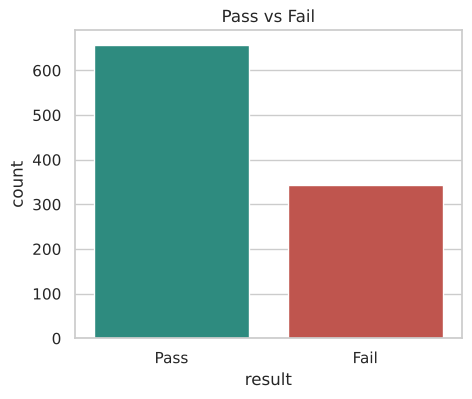

result
Pass    0.66
Fail    0.34
Name: proportion, dtype: float64


In [12]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="result", order=["Pass", "Fail"], palette=["#1E9A8A", "#D2453B"], hue="result", legend=False)
plt.title("Pass vs Fail")
plt.show()

print(df["result"].value_counts(normalize=True).round(2))

About **2 out of 3** students pass. The two groups are not equal, but both are big enough to learn from.

> 📘 **Class balance:** how many examples each group has. If one group is very small (like fraud cases), accuracy can fool us. Remember the "accuracy trap" from the theory class!

### 4.2 Does attendance matter?

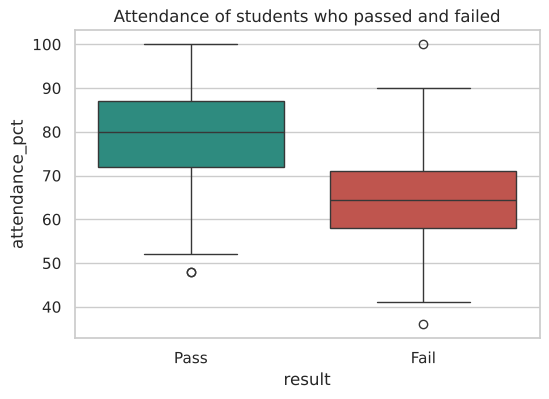

In [13]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="result", y="attendance_pct", order=["Pass", "Fail"], palette=["#1E9A8A", "#D2453B"], hue="result", legend=False)
plt.title("Attendance of students who passed and failed")
plt.show()

Students who **passed** usually have **higher attendance**. ✅

### 4.3 Study hours and quiz marks together

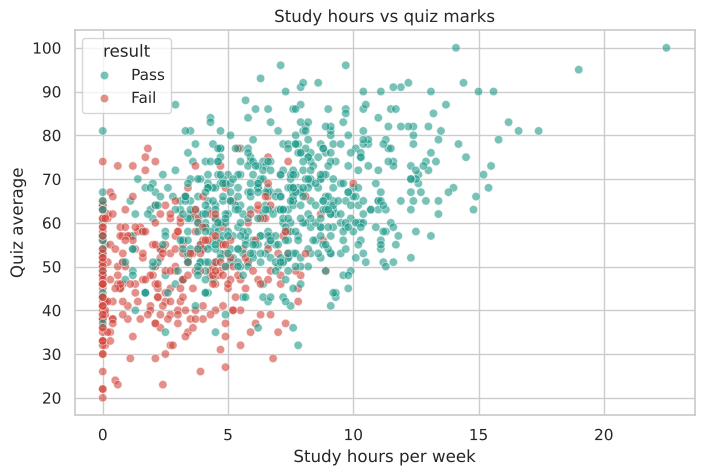

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="study_hours_week", y="quiz_avg", hue="result",
                palette={"Pass": "#1E9A8A", "Fail": "#D2453B"}, alpha=0.6)
plt.title("Study hours vs quiz marks")
plt.xlabel("Study hours per week")
plt.ylabel("Quiz average")
plt.show()

Green dots (Pass) are mostly in the **top right**: more study and better quizzes. The model will learn a **border** between green and red.

### 4.4 Does having a laptop help?

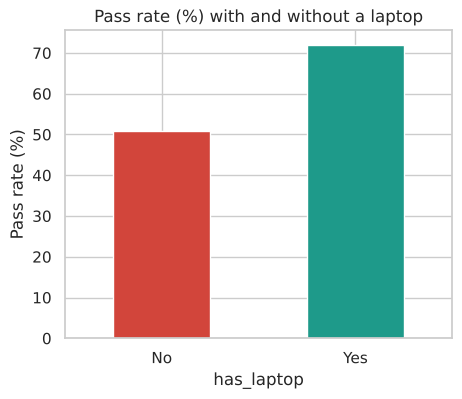

In [15]:
pass_rate = df.groupby("has_laptop")["result"].apply(lambda r: (r == "Pass").mean() * 100)

plt.figure(figsize=(5, 4))
pass_rate.plot(kind="bar", color=["#D2453B", "#1E9A8A"])
plt.title("Pass rate (%) with and without a laptop")
plt.ylabel("Pass rate (%)")
plt.xticks(rotation=0)
plt.show()

Students **with a laptop** pass more often. They can practise at home.

✏️ **Your turn:** make the same pass-rate chart for `part_time_job`. Do working students pass less?

In [16]:
# Write your code here

## Step 5 · Prepare the data for the model

The model only understands **numbers**.

### 5.1 The target: Pass → 1, Fail → 0

In [17]:
df["result"] = df["result"].map({"Pass": 1, "Fail": 0})
df["result"].value_counts()

result
1    657
0    343
Name: count, dtype: int64

### 5.2 Yes / No columns → 1 / 0

In [18]:
for col in ["has_laptop", "has_internet", "part_time_job", "programming_before"]:
    df[col] = df[col].map({"Yes": 1, "No": 0})

df[["has_laptop", "has_internet", "part_time_job", "programming_before"]].head()

,has_laptop,has_internet,part_time_job,programming_before
0,0.0,1,1,0
1,0.0,0,0,1
2,1.0,0,0,0
3,1.0,0,0,0
4,1.0,1,1,0


### 5.3 Education → 0, 1, 2, 3
Education has an **order**, so we number it in order.

In [19]:
education_numbers = {"Matric": 0, "Intermediate": 1, "Bachelors": 2, "Masters": 3}
df["education"] = df["education"].map(education_numbers)
df["education"].value_counts()

education
1    419
2    358
0    119
3    104
Name: count, dtype: int64

### 5.4 City → one-hot encoding
Cities have **no order**, so we make one 0/1 column for each city.

> 📘 **One-hot encoding:** one new column per category. 1 = "yes, this one", 0 = "no".

In [20]:
df = pd.get_dummies(df, columns=["city"], dtype=int)
df.head()

,age,education,study_hours_week,attendance_pct,quiz_avg,assignments_done,has_laptop,has_internet,part_time_job,programming_before,travel_time_min,result,city_Khairpur,city_Larkana,city_Rohri,city_Shikarpur,city_Sukkur
0,24,2,3.4,87.0,76.0,6,0.0,1,1,0,30,1,0,0,0,0,1
1,21,2,11.9,100.0,91.0,7,0.0,0,0,1,5,1,0,0,0,0,1
2,22,0,2.3,83.0,54.0,8,1.0,0,0,0,15,1,0,0,0,0,1
3,24,2,5.0,72.0,45.0,5,1.0,0,0,0,5,0,0,0,0,0,1
4,24,2,0.0,51.0,33.0,4,1.0,1,1,0,86,0,0,0,1,0,0


## Step 6 · Split the data into train and test

> 📘 **Training set** = what the model learns from (homework). **Test set** = hidden students for the final check (exam).

In [21]:
X = df.drop(columns=["result"])
y = df["result"]
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (1000, 16) | y shape: (1000,)


> 📘 **`stratify=y`** keeps the **same Pass/Fail ratio** in the training set and the test set. Without it, by bad luck, the test set might get too few Fail students.

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training students:", len(X_train), "| Pass rate:", round(y_train.mean(), 2))
print("Testing students :", len(X_test),  "| Pass rate:", round(y_test.mean(), 2))

Training students: 800 | Pass rate: 0.66
Testing students : 200 | Pass rate: 0.66


### 6.1 Fill the missing values (using the training set only)
- Numbers (`quiz_avg`, `attendance_pct`, `study_hours_week`) → **median**
- Yes/No (`has_laptop`) → **mode** (most common value)

In [23]:
fill_values = {
    "quiz_avg":         X_train["quiz_avg"].median(),
    "attendance_pct":   X_train["attendance_pct"].median(),
    "study_hours_week": X_train["study_hours_week"].median(),
    "has_laptop":       X_train["has_laptop"].mode()[0],
}
print("Fill values learned from the training data:")
for column, value in fill_values.items():
    print("  ", column, "→", float(value))

X_train = X_train.fillna(fill_values)
X_test  = X_test.fillna(fill_values)
print("Missing values left:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Fill values learned from the training data:
   quiz_avg → 59.0
   attendance_pct → 75.0
   study_hours_week → 5.25
   has_laptop → 1.0
Missing values left: 0


## Step 7 · Train the model: Logistic Regression

> 📘 **Logistic Regression** is a classification model (even though its name says "regression").
> It gives a **probability between 0 and 1**, for example *"0.82 = 82% chance to pass"*.
> If the probability is **0.5 or more → Pass**, otherwise **Fail**.

The steps are the same as Lab 1: **create → fit → predict**.

In [24]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)    # max_iter = give it enough steps to finish learning
model.fit(X_train, y_train)
print("Training finished! ✅")

Training finished! ✅


### 7.1 Probabilities and predictions
> 📘 **`predict_proba`** gives the probability of each class. **`predict`** gives the final answer (0 or 1).

In [25]:
pass_probability = model.predict_proba(X_test)[:, 1]     # column 1 = probability of Pass
y_pred = model.predict(X_test)

look = pd.DataFrame({
    "Real result":      y_test.map({1: "Pass", 0: "Fail"}).values,
    "Pass probability": pass_probability.round(2),
    "Model says":       pd.Series(y_pred).map({1: "Pass", 0: "Fail"}).values,
})
look.head(10)

,Real result,Pass probability,Model says
0,Pass,0.75,Pass
1,Pass,1.00,Pass
2,Pass,0.48,Fail
3,Pass,0.97,Pass
4,Fail,0.42,Fail
5,Pass,0.86,Pass
6,Pass,0.86,Pass
7,Fail,0.26,Fail
8,Fail,0.01,Fail
9,Pass,1.00,Pass


## Step 8 · Check how good the model is

### 8.1 Accuracy
> 📘 **Accuracy** = correct answers ÷ all answers.

In [26]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.1%}")

Accuracy: 83.5%


### 8.2 The confusion matrix
Accuracy alone does not tell us **what kind** of mistakes the model makes.

> 📘 **Confusion matrix:** a table comparing the **real** answer (rows) with the **model's** answer (columns).
> The diagonal (top-left to bottom-right) = correct answers. Everything else = mistakes.

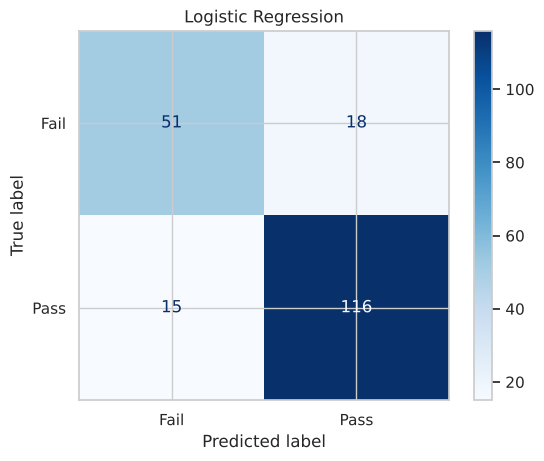

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Fail", "Pass"]).plot(cmap="Blues")
plt.title("Logistic Regression")
plt.show()

How to read it:
- **Top-left:** really Fail, model said Fail ✅ (we **caught** a student at risk)
- **Top-right:** really Fail, model said Pass ❌ (we **missed** a student at risk — the dangerous mistake!)
- **Bottom-left:** really Pass, model said Fail ❌ (a false alarm — the trainer checks on a student who was fine)
- **Bottom-right:** really Pass, model said Pass ✅

### 8.3 Precision, recall and F1

> 📘 **Precision:** when the model says "Fail", how often is it right?
> 📘 **Recall:** of all students who **really failed**, how many did the model find?
> 📘 **F1-score:** one number that balances precision and recall.

For our problem, **missing a student at risk is the worse mistake**. So we care most about the **recall of the Fail class**.

In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Fail", "Pass"]))

              precision    recall  f1-score   support

        Fail       0.77      0.74      0.76        69
        Pass       0.87      0.89      0.88       131

    accuracy                           0.83       200
   macro avg       0.82      0.81      0.82       200
weighted avg       0.83      0.83      0.83       200



In [29]:
from sklearn.metrics import recall_score

fail_recall = recall_score(y_test, y_pred, pos_label=0)     # pos_label=0 → look at the Fail class
print(f"Out of all students who really failed, we found {fail_recall:.0%}.")

Out of all students who really failed, we found 74%.


### 8.4 Catch more students at risk: change the threshold
By default the model says "Fail" only when the pass probability is **below 0.5**.
What if we are more careful, and call a student **at risk** when the pass probability is below **0.65**?

Threshold 0.50 → we find 74% of failing students
Threshold 0.65 → we find 83% of failing students


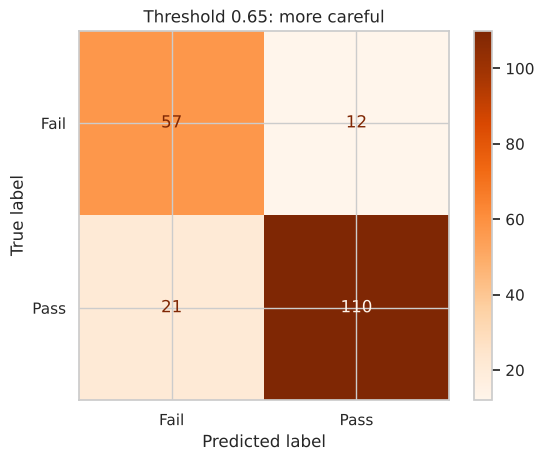

In [30]:
threshold = 0.65
y_pred_careful = (pass_probability >= threshold).astype(int)    # 1 = Pass, 0 = at risk

careful_recall = recall_score(y_test, y_pred_careful, pos_label=0)
print(f"Threshold 0.50 → we find {fail_recall:.0%} of failing students")
print(f"Threshold {threshold} → we find {careful_recall:.0%} of failing students")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_careful), display_labels=["Fail", "Pass"]).plot(cmap="Oranges")
plt.title(f"Threshold {threshold}: more careful")
plt.show()

✅ We now **catch more students at risk** (higher recall).
❌ But we also get **more false alarms** (some passing students are flagged).

This is the **precision–recall trade-off** from the theory class. For helping students, a few extra false alarms are OK — a trainer just talks to them.

## Step 9 · Try more models

### 9.1 Decision Tree
> 📘 **Decision Tree:** the model asks **yes/no questions**, one after another, like *"Is attendance above 70%?"*. At the end of each path is a decision: Pass or Fail.
> `max_depth=3` means **at most 3 questions** in a row, so the tree is small and easy to read.

In [31]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
print(f"Decision Tree accuracy: {accuracy_score(y_test, tree_pred):.1%}")

Decision Tree accuracy: 82.0%


Let's **see** the questions the tree learned:

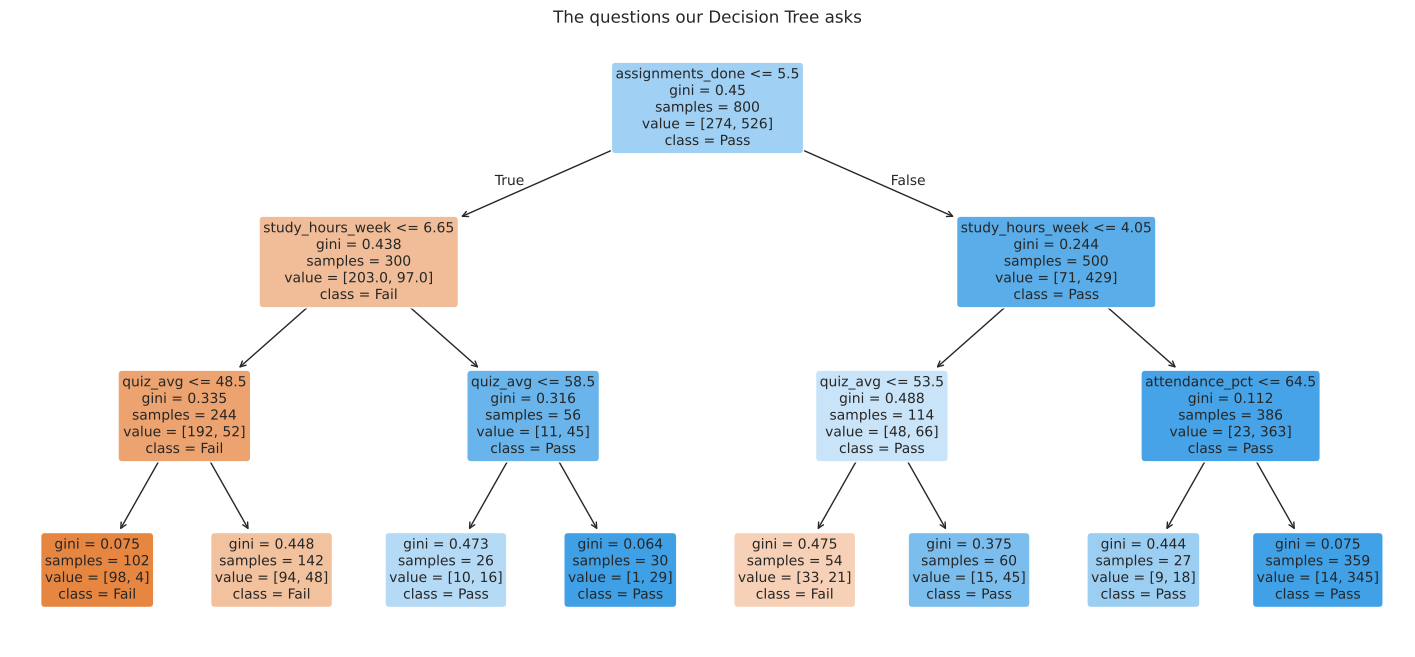

In [32]:
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=X_train.columns, class_names=["Fail", "Pass"],
          filled=True, rounded=True, fontsize=10)
plt.title("The questions our Decision Tree asks")
plt.show()

Read the tree from the **top box** down. Each box shows the question, and how many students went that way. Orange boxes lean to **Fail**, blue boxes lean to **Pass**.

### 9.2 Random Forest
> 📘 **Random Forest:** builds **many decision trees** and lets them **vote**. The majority answer wins. Usually more accurate than one tree.

In [33]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=200, random_state=42)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)
print(f"Random Forest accuracy: {accuracy_score(y_test, forest_pred):.1%}")

Random Forest accuracy: 83.0%


### 9.3 Compare the three models

In [34]:
from sklearn.metrics import f1_score

all_models = {"Logistic Regression": model, "Decision Tree": tree, "Random Forest": forest}

rows = []
for name, m in all_models.items():
    p = m.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, p), 3),
        "Fail recall": round(recall_score(y_test, p, pos_label=0), 3),
        "Fail F1": round(f1_score(y_test, p, pos_label=0), 3),
    })

results = pd.DataFrame(rows)
results

,Model,Accuracy,Fail recall,Fail F1
0,Logistic Regression,0.835,0.739,0.756
1,Decision Tree,0.820,0.739,0.739
2,Random Forest,0.830,0.667,0.730


> ℹ️ We compare on the test set to keep this lab simple. In a later lab we will learn **cross-validation**, the proper way to choose a model.

### 9.4 Which features matter most?

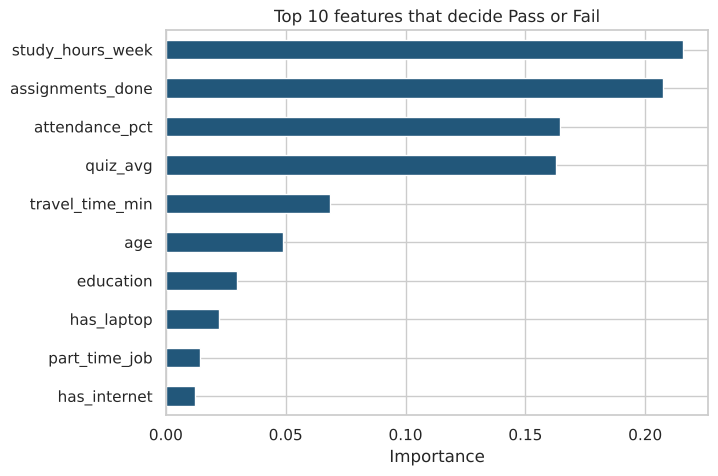

In [35]:
importance = pd.Series(forest.feature_importances_, index=X_train.columns)
importance = importance.sort_values().tail(10)

plt.figure(figsize=(7, 5))
importance.plot(kind="barh", color="#22577A")
plt.title("Top 10 features that decide Pass or Fail")
plt.xlabel("Importance")
plt.show()

**Quiz marks, attendance, study hours and assignments** matter most. This tells trainers what to watch! 👀

## Step 10 · Save the model and test it live 🎉

### 10.1 Save the best model
We keep the model with the best **Fail F1** (it catches failing students *and* does not raise too many false alarms).

> 📘 **joblib** saves a trained model into a file and loads it back later.

In [36]:
import joblib

best_name = results.sort_values("Fail F1", ascending=False).iloc[0]["Model"]
best_model = all_models[best_name]
print("Best model:", best_name)

joblib.dump(best_model, "student_model.pkl")
joblib.dump(list(X_train.columns), "student_model_columns.pkl")
print("Saved! ✅")

Best model: Logistic Regression
Saved! ✅


### 10.2 A function that predicts for any student
A new student must be prepared **exactly like** the training data (Yes → 1, education → number, city → one-hot).

> 📘 **Function:** a named block of code. We write it once and use it many times.

In [37]:
saved_model   = joblib.load("student_model.pkl")
saved_columns = joblib.load("student_model_columns.pkl")

def predict_student(city, age, education, study_hours_week, attendance_pct, quiz_avg,
                    assignments_done, has_laptop, has_internet, part_time_job,
                    programming_before, travel_time_min):
    # 0. check the spelling
    if "city_" + city not in saved_columns:
        print("⚠️ Unknown city:", city)
        return None
    if education not in education_numbers:
        print("⚠️ Education must be Matric, Intermediate, Bachelors or Masters")
        return None
    # 1. one-row table with the student's details
    student = pd.DataFrame([{
        "age": age,
        "education": education_numbers[education],
        "study_hours_week": study_hours_week,
        "attendance_pct": attendance_pct,
        "quiz_avg": quiz_avg,
        "assignments_done": assignments_done,
        "has_laptop": 1 if has_laptop == "Yes" else 0,
        "has_internet": 1 if has_internet == "Yes" else 0,
        "part_time_job": 1 if part_time_job == "Yes" else 0,
        "programming_before": 1 if programming_before == "Yes" else 0,
        "travel_time_min": travel_time_min,
        "city_" + city: 1,
    }])
    # 2. same columns as training (other cities become 0)
    student = student.reindex(columns=saved_columns, fill_value=0)
    # 3. probability of passing
    chance = saved_model.predict_proba(student)[0, 1]
    if chance >= 0.5:
        print(f"✅ PASS — {chance:.0%} chance to pass")
    else:
        print(f"⚠️ AT RISK — only {chance:.0%} chance to pass. Please give this student extra help!")
    return chance

print("Function ready ✅")

Function ready ✅


### 10.3 Try it: change the values and run the cell

In [38]:
predict_student(
    city="Sukkur",               # Sukkur, Rohri, Shikarpur, Khairpur, Larkana
    age=21,
    education="Intermediate",    # Matric, Intermediate, Bachelors, Masters
    study_hours_week=5,
    attendance_pct=75,
    quiz_avg=58,
    assignments_done=6,
    has_laptop="Yes",
    has_internet="Yes",
    part_time_job="No",
    programming_before="No",
    travel_time_min=20,
);

✅ PASS — 86% chance to pass


In [39]:
# A student with similar marks, but no laptop, a part-time job and a longer travel time
predict_student(city="Rohri", age=22, education="Intermediate", study_hours_week=4,
                attendance_pct=70, quiz_avg=55, assignments_done=5, has_laptop="No",
                has_internet="Yes", part_time_job="Yes", programming_before="No",
                travel_time_min=40);

⚠️ AT RISK — only 21% chance to pass. Please give this student extra help!


### 10.4 🎤 Live test: type a student's details!
Run the cell below. It will **ask you questions**. Type an answer and press **Enter**.

In [ ]:
print("Answer each question and press Enter.\n")
city   = input("City (Sukkur, Rohri, Shikarpur, Khairpur, Larkana): ").strip().title()
age    = int(input("Age: "))
edu    = input("Education (Matric, Intermediate, Bachelors, Masters): ").strip().title()
study  = float(input("Study hours per week: "))
att    = float(input("Attendance % (0-100): "))
quiz   = float(input("Quiz average (0-100): "))
assign = int(input("Assignments done (0-10): "))
laptop = input("Has a laptop? (Yes/No): ").strip().title()
net    = input("Has internet at home? (Yes/No): ").strip().title()
job    = input("Part-time job? (Yes/No): ").strip().title()
prog   = input("Learned programming before? (Yes/No): ").strip().title()
travel = int(input("Travel time to class (minutes): "))

print()
predict_student(city, age, edu, study, att, quiz, assign, laptop, net, job, prog, travel);

## Step 11 · Bonus: make it a web app with Streamlit 🌐

A notebook is for programmers. A teacher or a student wants a **simple web page**: fill in the details, click a button, see the answer.

> 📘 **Streamlit** is a Python library that turns a Python script into a **web app**, with no HTML or JavaScript needed.

### 11.1 Install Streamlit (only once)
Run this cell. It may take a minute.

In [ ]:
%pip install streamlit

### 11.2 Write the app file
The cell below **writes a file called `student_app.py`** into this folder.
> 📘 **`%%writefile`** saves everything in the cell into a file, instead of running it.

The app uses the model we saved in Step 10 (`student_model.pkl`), so make sure you ran Step 10 first.

In [41]:
%%writefile student_app.py
import streamlit as st
import pandas as pd
import joblib

# 1. Load the saved model and its column list (made in Step 10 of the notebook)
model = joblib.load("student_model.pkl")
columns = joblib.load("student_model_columns.pkl")
education_numbers = {"Matric": 0, "Intermediate": 1, "Bachelors": 2, "Masters": 3}

# 2. Page title
st.set_page_config(page_title="Student Pass Predictor", page_icon="🎓")
st.title("🎓 Will this student pass?")
st.write("Enter the student's details and click **Predict**.")

# 3. Input boxes, in two columns
left, right = st.columns(2)
with left:
    city = st.selectbox("City", ["Sukkur", "Rohri", "Shikarpur", "Khairpur", "Larkana"])
    age = st.number_input("Age", min_value=15, max_value=40, value=21)
    education = st.selectbox("Education", ["Matric", "Intermediate", "Bachelors", "Masters"], index=1)
    study_hours = st.slider("Study hours per week", 0.0, 25.0, 5.0, step=0.5)
    attendance = st.slider("Attendance (%)", 0, 100, 75)
    quiz = st.slider("Quiz average (out of 100)", 0, 100, 58)
with right:
    assignments = st.slider("Assignments done (out of 10)", 0, 10, 6)
    travel = st.number_input("Travel time to class (minutes)", min_value=0, max_value=180, value=20)
    laptop = st.radio("Has a laptop?", ["Yes", "No"], horizontal=True)
    internet = st.radio("Has internet at home?", ["Yes", "No"], horizontal=True)
    job = st.radio("Part-time job?", ["No", "Yes"], horizontal=True)
    programming = st.radio("Learned programming before?", ["No", "Yes"], horizontal=True)

# 4. When the button is clicked: prepare the data exactly like in the notebook, then predict
if st.button("Predict", type="primary"):
    student = pd.DataFrame([{
        "age": age,
        "education": education_numbers[education],
        "study_hours_week": study_hours,
        "attendance_pct": attendance,
        "quiz_avg": quiz,
        "assignments_done": assignments,
        "has_laptop": 1 if laptop == "Yes" else 0,
        "has_internet": 1 if internet == "Yes" else 0,
        "part_time_job": 1 if job == "Yes" else 0,
        "programming_before": 1 if programming == "Yes" else 0,
        "travel_time_min": travel,
        "city_" + city: 1,
    }])
    student = student.reindex(columns=columns, fill_value=0)
    chance = model.predict_proba(student)[0, 1]

    st.progress(float(chance), text=f"Chance to pass: {chance:.0%}")
    if chance >= 0.5:
        st.success(f"✅ PASS — {chance:.0%} chance to pass")
    else:
        st.error(f"⚠️ AT RISK — only {chance:.0%} chance to pass. Please give this student extra help!")

Overwriting student_app.py


### 11.3 Run the app
Streamlit apps run from the **terminal** (Command Prompt / Anaconda Prompt), not inside the notebook.

1. Open **Anaconda Prompt** (or Command Prompt).
2. Go to the folder of this notebook, for example:
   ```
   cd "D:\AI & Data Science Course\06 - Machine Learning\Classification\Lab 2 - Student Pass or Fail"
   ```
3. Run:
   ```
   streamlit run student_app.py
   ```
4. Your browser opens the app at **http://localhost:8501** 🎉
5. To stop the app, go back to the terminal and press **Ctrl + C**.

**How the code works, line by line:**
- `st.title`, `st.write` → show text on the page
- `st.selectbox`, `st.slider`, `st.number_input`, `st.radio` → input boxes for the user
- `st.button` → the "Predict" button; the code under `if st.button(...)` runs only when it is clicked
- `st.success` / `st.error` → a green or red message box
- `st.progress` → a bar that shows the probability

✏️ **Your turn:** add a new message: if the chance is between 50% and 65%, show `st.warning("Borderline — keep an eye on this student")`.

## 🎉 Well done!

You built a complete **classification** project:
**problem → load → clean → explore → prepare → split → train → confusion matrix → precision & recall → threshold → more models → save → predict → web app**.

### Regression (Lab 1) vs Classification (Lab 2)

| | Lab 1: Regression | Lab 2: Classification |
|---|---|---|
| Predicts | a **number** (price) | a **group** (Pass / Fail) |
| Models | LinearRegression, RandomForestRegressor | LogisticRegression, DecisionTreeClassifier, RandomForestClassifier |
| Scores | MAE, RMSE, R² | Accuracy, confusion matrix, precision, recall, F1 |

### ✏️ Practice tasks
1. Make a pass-rate chart for `programming_before`. Does learning programming before help?
2. Change the Decision Tree to `max_depth=2` and then `max_depth=10`. What happens to accuracy? Which one overfits?
3. Try the threshold **0.75**. How many failing students do we catch now? How many false alarms?
4. **Leakage test:** load the CSV again and keep `final_exam_score`. Train the model. Why is the accuracy now "too good to be true"?
5. Use the live test to check **yourself**: enter your own study hours and attendance! 😄